In [1]:
from pathlib import Path
import pandas as pd

# Raíz del proyecto
ROOT_DIR = Path.cwd().parent

# Ruta del dataset
DATA_PATH = ROOT_DIR / "data" / "raw" / "ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dimensiones: {df.shape}")
display(df.head())

Dimensiones: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
# Dimensiones del dataset
print("Dimensiones:", df.shape)

# Nombres de las columnas
print("\nColumnas:")
print(df.columns.tolist())

# Tipos de datos y valores no nulos
print("\nInformación general:")
df.info()

# Primeras 5 observaciones
display(df.head())


Dimensiones: (10000, 14)

Columnas:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Valores faltantes por columna
print("Valores faltantes:")
display(df.isnull().sum())

# Registros duplicados
print("Registros duplicados:", df.duplicated().sum())

# Distribución de la variable objetivo
print("\nDistribución de fallas:")
display(df["Machine failure"].value_counts())

# Porcentaje por clase
display(
    df["Machine failure"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Valores faltantes:


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Registros duplicados: 0

Distribución de fallas:


Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

In [4]:
### dataset no esta equilibrado y accuracy no seria de mucha ayuda

In [5]:
# Seleccionar variables para el análisis
FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

TARGET = "Machine failure"

df_modelo = df[FEATURES + [TARGET]].copy()

# Estadísticas descriptivas
display(df_modelo.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0


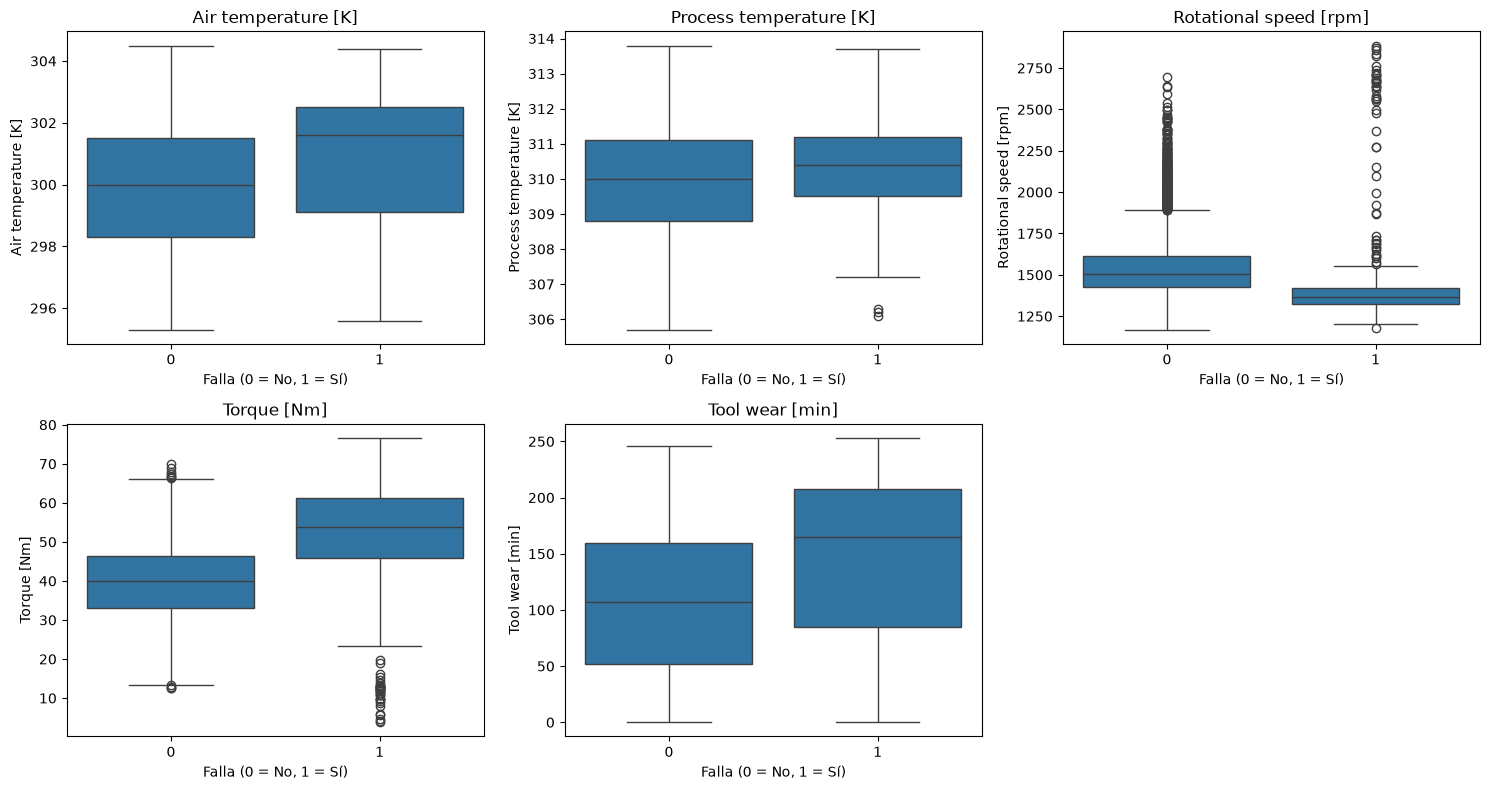

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = [
    col for col in FEATURES
    if col != "Type"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, numeric_features):
    sns.boxplot(
        data=df_modelo,
        x="Machine failure",
        y=feature,
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Falla (0 = No, 1 = Sí)")

# Eliminar el eje sobrante
for ax in axes.flat[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [7]:
##### torque a simple vista y roatational speed son las variables que si presentan casi distintos rangos

In [8]:
# Cantidad de registros por tipo de producto y falla
tabla_type = pd.crosstab(
    df_modelo["Type"],
    df_modelo[TARGET]
)

display(tabla_type)

# Porcentaje de falla dentro de cada tipo
tasa_falla = (
    df_modelo.groupby("Type")[TARGET]
    .agg(["count", "sum", "mean"])
)

tasa_falla["mean"] = tasa_falla["mean"] * 100
tasa_falla.columns = [
    "Total registros",
    "Cantidad de fallas",
    "Tasa de falla (%)"
]

display(tasa_falla.round(2))

Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


,Total registros,Cantidad de fallas,Tasa de falla (%)
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


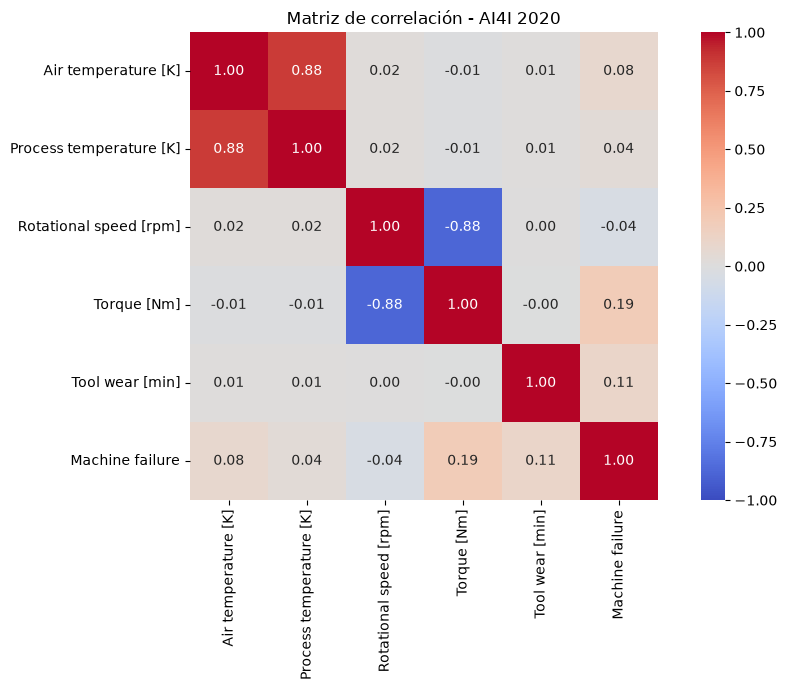

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Variables numéricas y variable objetivo
df_corr = df_modelo.select_dtypes(include="number")

# Correlación de Pearson
corr_matrix = df_corr.corr(method="pearson")

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Matriz de correlación - AI4I 2020")
plt.tight_layout()
plt.show()

In [10]:
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

### 4.Entrenamiento y comparacion de modelos

In [11]:
from sklearn.model_selection import train_test_split

X = df_modelo.drop(columns="Machine failure")
y = df_modelo["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nClases en entrenamiento:")
print(y_train.value_counts())

print("\nClases en prueba:")
print(y_test.value_counts())

Entrenamiento: (8000, 6)
Prueba: (2000, 6)

Clases en entrenamiento:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Clases en prueba:
Machine failure
0    1932
1      68
Name: count, dtype: int64


### 4.1. Modelo base: DummyClassifier

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

dummy = DummyClassifier(strategy="most_frequent")

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "pr_auc": "average_precision"
}

scores_dummy = cross_validate(
    dummy,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metrica in scoring:
    print(f"{metrica}: {scores_dummy[f'test_{metrica}'].mean():.4f}")

accuracy: 0.9661
precision: 0.0000
recall: 0.0000
f1: 0.0000
pr_auc: 0.0339


c:\Users\SAHUA\Documents\proyecto_final_mlops_11\ai4i-mlops\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\SAHUA\Documents\proyecto_final_mlops_11\ai4i-mlops\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\SAHUA\Documents\proyecto_final_mlops_11\ai4i-mlops\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

logistic = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=SEED
    ))
])

In [14]:
scores_logistic = cross_validate(
    logistic,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metrica in scoring:
    print(f"{metrica}: {scores_logistic[f'test_{metrica}'].mean():.4f}")

accuracy: 0.8225
precision: 0.1374
recall: 0.8044
f1: 0.2346
pr_auc: 0.4409


In [15]:
resultados = pd.DataFrame({
    "DummyClassifier": {
        metrica: scores_dummy[f"test_{metrica}"].mean()
        for metrica in scoring
    },
    "LogisticRegression": {
        metrica: scores_logistic[f"test_{metrica}"].mean()
        for metrica in scoring
    }
}).T

display(resultados.round(4))

,accuracy,precision,recall,f1,pr_auc
DummyClassifier,0.9661,0.0000,0.0000,0.0000,0.0339
LogisticRegression,0.8225,0.1374,0.8044,0.2346,0.4409


In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Type"])
    ],
    remainder="passthrough"
)

tree = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=SEED
    ))
])

In [17]:
scores_tree = cross_validate(
    tree,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metrica in scoring:
    print(f"{metrica}: {scores_tree[f'test_{metrica}'].mean():.4f}")

accuracy: 0.9284
precision: 0.3038
recall: 0.8600
f1: 0.4485
pr_auc: 0.5263


In [18]:
resultados = pd.DataFrame({
    "DummyClassifier": {
        m: scores_dummy[f"test_{m}"].mean()
        for m in scoring
    },
    "LogisticRegression": {
        m: scores_logistic[f"test_{m}"].mean()
        for m in scoring
    },
    "DecisionTree": {
        m: scores_tree[f"test_{m}"].mean()
        for m in scoring
    }
}).T

display(resultados.round(4))

,accuracy,precision,recall,f1,pr_auc
DummyClassifier,0.9661,0.0000,0.0000,0.0000,0.0339
LogisticRegression,0.8225,0.1374,0.8044,0.2346,0.4409
DecisionTree,0.9284,0.3038,0.8600,0.4485,0.5263


In [19]:
from sklearn.ensemble import RandomForestClassifier

forest = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ))
])

In [20]:
scores_forest = cross_validate(
    forest,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metrica in scoring:
    print(f"{metrica}: {scores_forest[f'test_{metrica}'].mean():.4f}")

accuracy: 0.9062
precision: 0.2483
recall: 0.8636
f1: 0.3853
pr_auc: 0.5337


In [21]:
resultados = pd.DataFrame({
    "DummyClassifier": {
        m: scores_dummy[f"test_{m}"].mean()
        for m in scoring
    },
    "LogisticRegression": {
        m: scores_logistic[f"test_{m}"].mean()
        for m in scoring
    },
    "DecisionTree": {
        m: scores_tree[f"test_{m}"].mean()
        for m in scoring
    },
    "RandomForest": {
        m: scores_forest[f"test_{m}"].mean()
        for m in scoring
    }
}).T

display(resultados.round(4))


,accuracy,precision,recall,f1,pr_auc
DummyClassifier,0.9661,0.0000,0.0000,0.0000,0.0339
LogisticRegression,0.8225,0.1374,0.8044,0.2346,0.4409
DecisionTree,0.9284,0.3038,0.8600,0.4485,0.5263
RandomForest,0.9062,0.2483,0.8636,0.3853,0.5337


In [22]:
from sklearn.ensemble import HistGradientBoostingClassifier

boosting = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        max_leaf_nodes=15,
        learning_rate=0.1,
        class_weight="balanced",
        random_state=SEED
    ))
])

In [23]:
scores_boosting = cross_validate(
    boosting,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metrica in scoring:
    print(f"{metrica}: {scores_boosting[f'test_{metrica}'].mean():.4f}")

accuracy: 0.9699
precision: 0.5406
recall: 0.8265
f1: 0.6527
pr_auc: 0.7900


In [24]:
scores_modelos = {
    "Dummy": scores_dummy,
    "LogisticRegression": scores_logistic,
    "DecisionTree": scores_tree,
    "RandomForest": scores_forest,
    "HistGradientBoosting": scores_boosting
}

resultados = pd.DataFrame({
    nombre: {
        metrica: scores[f"test_{metrica}"].mean()
        for metrica in scoring
    }
    for nombre, scores in scores_modelos.items()
}).T

display(resultados.round(4))

,accuracy,precision,recall,f1,pr_auc
Dummy,0.9661,0.0000,0.0000,0.0000,0.0339
LogisticRegression,0.8225,0.1374,0.8044,0.2346,0.4409
DecisionTree,0.9284,0.3038,0.8600,0.4485,0.5263
RandomForest,0.9062,0.2483,0.8636,0.3853,0.5337
HistGradientBoosting,0.9699,0.5406,0.8265,0.6527,0.7900


In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__max_iter": [100, 200],
    "model__max_leaf_nodes": [7, 15],
    "model__learning_rate": [0.05, 0.1],
    "model__l2_regularization": [0.0, 1.0]
}

In [26]:
grid_boosting = GridSearchCV(
    estimator=boosting,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_boosting.fit(X_train, y_train)

print("Mejores parámetros:")
print(grid_boosting.best_params_)

print(f"\nMejor Average Precision CV: {grid_boosting.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Mejores parámetros:
{'model__l2_regularization': 0.0, 'model__learning_rate': 0.1, 'model__max_iter': 200, 'model__max_leaf_nodes': 15}

Mejor Average Precision CV: 0.7922


In [27]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

mlp = Pipeline([
    ("preprocessor", preprocessor),
    ("model", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        alpha=0.01,
        max_iter=500,
        early_stopping=True,
        random_state=SEED
    ))
])

scores_mlp = cross_validate(
    mlp,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metrica in scoring:
    print(f"{metrica}: {scores_mlp[f'test_{metrica}'].mean():.4f}")

accuracy: 0.9714
precision: 0.7642
recall: 0.2180
f1: 0.3372
pr_auc: 0.5041


In [28]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

mejor_modelo = grid_boosting.best_estimator_

y_proba_cv = cross_val_predict(
    mejor_modelo,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_train,
    y_proba_cv
)

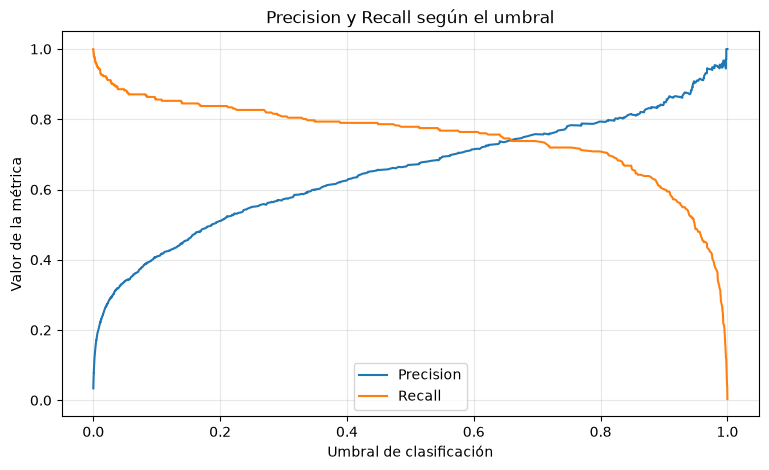

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.xlabel("Umbral de clasificación")
plt.ylabel("Valor de la métrica")
plt.title("Precision y Recall según el umbral")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [30]:
from sklearn.inspection import permutation_importance

# Reservamos parte de entrenamiento para analizar importancia
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=SEED,
    stratify=y_train
)

modelo_importancia = clone(grid_boosting.best_estimator_)
modelo_importancia.fit(X_fit, y_fit)

importance = permutation_importance(
    modelo_importancia,
    X_val,
    y_val,
    n_repeats=10,
    random_state=SEED,
    scoring="average_precision",
    n_jobs=-1
)

In [31]:
import pandas as pd

df_importancia = pd.DataFrame({
    "Variable": X_val.columns,
    "Importancia": importance.importances_mean,
    "Desviación": importance.importances_std
})

df_importancia = df_importancia.sort_values(
    "Importancia",
    ascending=False
)

display(df_importancia.round(4))

,Variable,Importancia,Desviación
4,Torque [Nm],0.5283,0.0166
1,Air temperature [K],0.3753,0.0237
3,Rotational speed [rpm],0.2581,0.0316
2,Process temperature [K],0.2515,0.0167
5,Tool wear [min],0.2312,0.0208
0,Type,0.0343,0.0138


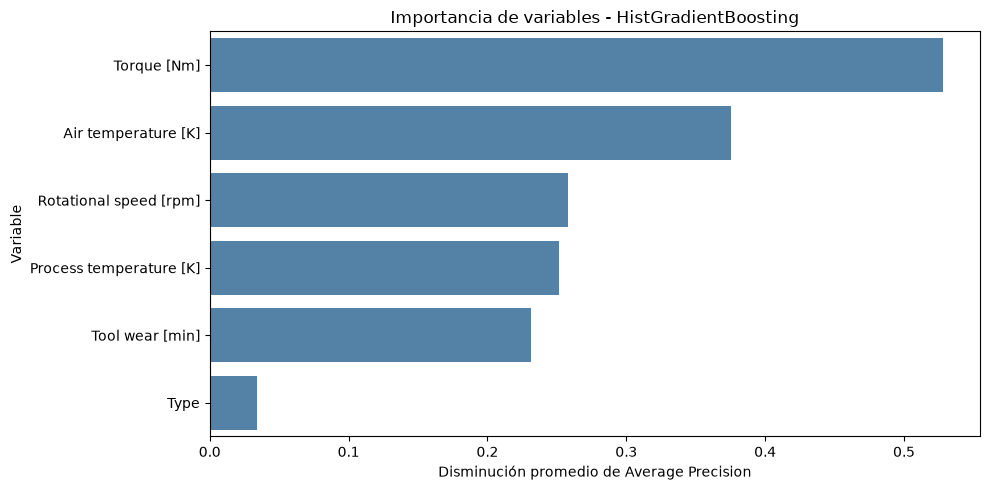

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_importancia,
    x="Importancia",
    y="Variable",
    color="steelblue"
)

plt.xlabel("Disminución promedio de Average Precision")
plt.ylabel("Variable")
plt.title("Importancia de variables - HistGradientBoosting")
plt.tight_layout()
plt.show()

In [33]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

modelo_sin_type = Pipeline([
    ("model", clone(grid_boosting.best_estimator_.named_steps["model"]))
])

X_train_numeric = X_train[numeric_features]

In [34]:
from sklearn.model_selection import cross_validate

scores_completo = cross_validate(
    grid_boosting.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

scores_sin_type = cross_validate(
    modelo_sin_type,
    X_train_numeric,
    y_train,
    cv=cv,
    scoring=scoring
)

comparacion_features = pd.DataFrame({
    "6 variables": {
        m: scores_completo[f"test_{m}"].mean()
        for m in scoring
    },
    "5 variables (sin Type)": {
        m: scores_sin_type[f"test_{m}"].mean()
        for m in scoring
    }
}).T

display(comparacion_features.round(4))

,accuracy,precision,recall,f1,pr_auc
6 variables,0.9796,0.6765,0.7785,0.7230,0.7922
5 variables (sin Type),0.9781,0.6561,0.7565,0.7015,0.7544


In [35]:
import numpy as np
import pandas as pd

# Calcular F1 para cada umbral
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Identificar el umbral que maximiza F1
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Mejor umbral F1: {best_threshold:.4f}")
print(f"Precision: {precision[best_idx]:.4f}")
print(f"Recall: {recall[best_idx]:.4f}")
print(f"F1: {f1_scores[best_idx]:.4f}")

Mejor umbral F1: 0.7531
Precision: 0.7831
Recall: 0.7196
F1: 0.7500


In [36]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

umbrales = [0.5, best_threshold]
resultados_umbrales = []

for umbral in umbrales:
    y_pred = (y_proba_cv >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, y_pred
    ).ravel()

    resultados_umbrales.append({
        "Umbral": round(umbral, 4),
        "Precision": precision_score(y_train, y_pred),
        "Recall": recall_score(y_train, y_pred),
        "F1": f1_score(y_train, y_pred),
        "FP": fp,
        "FN": fn
    })

comparacion_umbrales = pd.DataFrame(resultados_umbrales)

display(comparacion_umbrales.round(4))

,Umbral,Precision,Recall,F1,FP,FN
0,0.5000,0.6720,0.7786,0.7214,103,60
1,0.7531,0.7831,0.7196,0.7500,54,76


## 5. Evaluación final del modelo seleccionado

Accuracy: 0.9815
Precision: 0.7067
Recall: 0.7794
F1: 0.7413
Average Precision: 0.8479

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.71      0.78      0.74        68

    accuracy                           0.98      2000
   macro avg       0.85      0.88      0.87      2000
weighted avg       0.98      0.98      0.98      2000



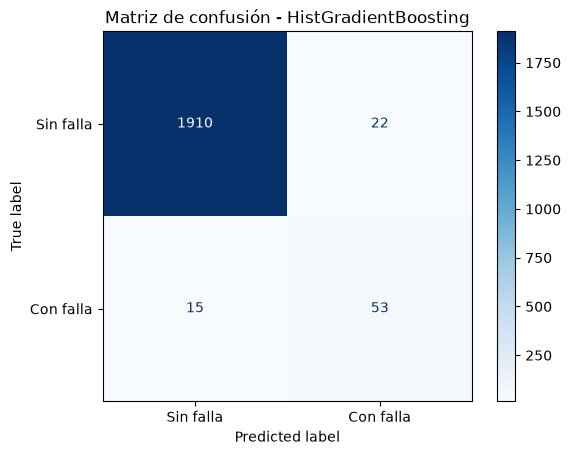

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Modelo optimizado
modelo_final = grid_boosting.best_estimator_

# Probabilidades sobre el conjunto de prueba
y_proba_test = modelo_final.predict_proba(X_test)[:, 1]

# Umbral seleccionado antes de evaluar el test
THRESHOLD = 0.50
y_pred_test = (y_proba_test >= THRESHOLD).astype(int)

# Métricas finales
print(f"Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_test):.4f}")
print(f"F1: {f1_score(y_test, y_pred_test):.4f}")
print(f"Average Precision: {average_precision_score(y_test, y_proba_test):.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_test))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=["Sin falla", "Con falla"],
    cmap="Blues"
)

plt.title("Matriz de confusión - HistGradientBoosting")
plt.show()